# Neuro-Symbolic Causal Inference on Corr2Cause
**Pipeline:** text → candidate causal triples (AML baseline vs DistilBERT, symbolic oracle as reference)
→ reviewed DAG per premise → Bayesian network (pgmpy) → intervention queries.

**Reproduce:** `pip install -r requirements.txt`, `python -m c2c.bert` once (~1.5 h on an M3 Pro),
then `jupytext --to ipynb --execute project1_causal.py`.

In [1]:
import pathlib

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support
from transformers import AutoTokenizer

from c2c import aml, bert
from c2c.bn import query_table
from c2c.data import load_splits, parse_hypothesis, parse_premise, renamed, train_subset
from c2c.graph import best_threshold, build_dag, edge_scores, gold_edges
from c2c.oracle import entailed

OUT = pathlib.Path("results")
OUT.mkdir(exist_ok=True)
SYSTEMS = ["AML (pattern LR)", "DistilBERT", "Symbolic oracle"]

s = load_splits()
train, val, test = train_subset(s["train"]), s["validation"], s["test"]
evalsets = {"val": val, "test": test, "test_renamed": renamed(test)}
pd.DataFrame({k: {"rows": len(v), "premises": v.doc_id.nunique(), "positive_rate": round(v.label.mean(), 3)}
              for k, v in s.items()}).T

/Users/abhis/Desktop/dlaml/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/abhis/Desktop/dlaml/.venv/lib/python3.12/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


,rows,premises,positive_rate
train,205626.0,2336.0,0.185
validation,1026.0,19.0,0.126
test,1162.0,21.0,0.155


## 1. Data facts
Positive rate per hypothesis template. `child` ("B directly causes A") is never positive: the generator
orders causes alphabetically, a shortcut a text model can learn. The renamed test set removes it.

In [2]:
s["train"].groupby("template").label.mean().round(3)

template
child                   0.000
has_collider            0.352
has_confounder          0.152
non-child descendant    0.126
non-parent ancestor     0.124
parent                  0.355
Name: label, dtype: float64

In [3]:
tok = AutoTokenizer.from_pretrained(bert.BASE)
pd.DataFrame({k: {"share_over_512_tokens": np.mean([len(ids) > bert.MAX_LEN for ids in
                                                      tok(list(df.premise), list(df.hypothesis))["input_ids"]])}
              for k, df in {"train_subset": train, **evalsets}.items()}).T.round(3)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (796 > 512). Running this sequence through the model will result in indexing errors


,share_over_512_tokens
train_subset,0.377
val,0.236
test,0.000
test_renamed,0.000


## 2. Relation extraction: which candidate causal triples does the text support?

In [4]:
model = aml.train_aml(train)
preds = {}
for k, df in evalsets.items():
    preds["AML (pattern LR)", k] = aml.predict_proba(model, df)
    preds["DistilBERT", k] = bert.predict_proba(df)
    preds["Symbolic oracle", k] = np.array([float(entailed(p, h)) for p, h in zip(df.premise, df.hypothesis)])
thresholds = {m: best_threshold(val.label, preds[m, "val"]) for m in SYSTEMS}  # tuned on validation only
thresholds

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 9409.95it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 7440.13it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 7290.54it/s]

{'AML (pattern LR)': 0.765875153848109,
 'DistilBERT': 0.21756881475448608,
 'Symbolic oracle': 1.0}

In [5]:
def prf(y, yhat):
    p, r, f, _ = precision_recall_fscore_support(y, yhat, average="binary", zero_division=0)
    return {"precision": p, "recall": r, "f1": f, "n": len(y)}


rows, per_row = [], []
for k in ("test", "test_renamed"):
    df = evalsets[k].assign(relation=lambda d: d.hypothesis.map(lambda h: parse_hypothesis(h)[0]))
    for m in SYSTEMS:
        d = df.assign(system=m, prob=preds[m, k], pred=preds[m, k] >= thresholds[m], set=k)
        per_row.append(d[["set", "system", "row_id", "doc_id", "template", "hypothesis", "label", "prob", "pred"]])
        rows.append({"set": k, "system": m, "relation": "all"} | prf(d.label, d.pred))
        rows += [{"set": k, "system": m, "relation": r} | prf(g.label, g.pred) for r, g in d.groupby("relation")]
extraction = pd.DataFrame(rows)
extraction.to_csv(OUT / "extraction_metrics.csv", index=False)
pd.concat(per_row).to_csv(OUT / "predictions.csv", index=False)
extraction[extraction.relation == "all"].round(3)

,set,system,relation,precision,recall,f1,n
0,test,AML (pattern LR),all,0.596,0.639,0.617,1162
5,test,DistilBERT,all,0.479,0.822,0.605,1162
10,test,Symbolic oracle,all,0.920,0.828,0.871,1162
15,test_renamed,AML (pattern LR),all,0.279,0.278,0.279,1162
20,test_renamed,DistilBERT,all,0.224,0.322,0.264,1162
25,test_renamed,Symbolic oracle,all,0.920,0.828,0.871,1162


In [6]:
extraction[extraction.set == "test"].pivot(index="relation", columns="system", values="f1").round(3)

system,AML (pattern LR),DistilBERT,Symbolic oracle
relation,,,
all,0.617,0.605,0.871
collider,0.667,0.564,0.894
confounder,0.000,0.743,0.875
direct,0.703,0.610,0.942
indirect,0.452,0.657,0.612


## 3. Label audit: where the symbolic oracle and the dataset disagree
Worked example: a premise says A⊥B marginally and given C or D, but never given E. E is then a collider,
so A→E holds in every DAG consistent with the premise, yet the dataset labels "A directly causes E" as 0.

In [7]:
audit = test.assign(oracle=preds["Symbolic oracle", "test"].astype(int))
audit = audit[audit.oracle != audit.label][["doc_id", "template", "hypothesis", "label", "oracle", "premise"]]
audit.to_csv(OUT / "label_audit.csv", index=False)
print(f"{len(audit)} of {len(test)} test rows disagree, across {audit.doc_id.nunique()} premises")
audit.drop(columns="premise").head(10)

44 of 1162 test rows disagree, across 12 premises


,doc_id,template,hypothesis,label,oracle
115,aa0fe548b9,has_collider,"There exists at least one collider (i.e., comm...",0,1
232,ac6a2ec8c0,non-parent ancestor,B causes something else which causes D.,1,0
240,ac6a2ec8c0,non-parent ancestor,A causes something else which causes E.,1,0
285,36356c9186,non-child descendant,"A is a cause for D, but not a direct one.",1,0
321,6d5cdc319b,parent,A directly causes E.,0,1
458,6d5cdc319b,non-child descendant,"C is a cause for E, but not a direct one.",0,1
553,aa8fc63098,has_collider,"There exists at least one collider (i.e., comm...",0,1
574,6d5cdc319b,has_collider,"There exists at least one collider (i.e., comm...",1,0
631,b79ddb8c68,has_collider,"There exists at least one collider (i.e., comm...",0,1
663,c0b5cdd875,non-child descendant,"B is a cause for E, but not a direct one.",1,0


## 4. Graph stage: reviewed predictions → one DAG per premise

In [8]:
graphs, edge_rows = {}, []
for k in ("test", "test_renamed"):
    df = evalsets[k]
    gold = {d: gold_edges(g) for d, g in df.groupby("doc_id")}
    for m in SYSTEMS:
        graphs[m, k] = {d: build_dag(g, thresholds[m]) for d, g in df.assign(prob=preds[m, k]).groupby("doc_id")}
        pred = {d: set(g.edges) for d, g in graphs[m, k].items()}
        # gated "direct" triples minus kept edges = edges the review rules dropped (self loops, conflicts, cycles)
        gated = sum(parse_hypothesis(h)[0] == "direct" and p >= thresholds[m] for h, p in zip(df.hypothesis, preds[m, k]))
        edge_rows.append({"set": k, "system": m} | edge_scores(pred, gold)
                         | {"removed_by_review": int(gated - sum(map(len, pred.values())))})
graph_metrics = pd.DataFrame(edge_rows)
graph_metrics.to_csv(OUT / "graph_metrics.csv", index=False)
pd.DataFrame([{"system": m, "cause": u, "effect": v, **a} for m in SYSTEMS
              for g in graphs[m, "test"].values() for u, v, a in g.edges(data=True)]
             ).to_csv(OUT / "edges_for_review.csv", index=False)
graph_metrics.round(3)

,set,system,edge_precision,edge_recall,edge_f1,tp,fp,fn,removed_by_review
0,test,AML (pattern LR),0.542,1.000,0.703,65,55,0,0
1,test,DistilBERT,0.505,0.769,0.610,50,49,15,0
2,test,Symbolic oracle,0.890,1.000,0.942,65,8,0,0
3,test_renamed,AML (pattern LR),0.200,0.369,0.259,24,96,41,0
4,test_renamed,DistilBERT,0.161,0.138,0.149,9,47,56,0
5,test_renamed,Symbolic oracle,0.890,1.000,0.942,65,8,0,0


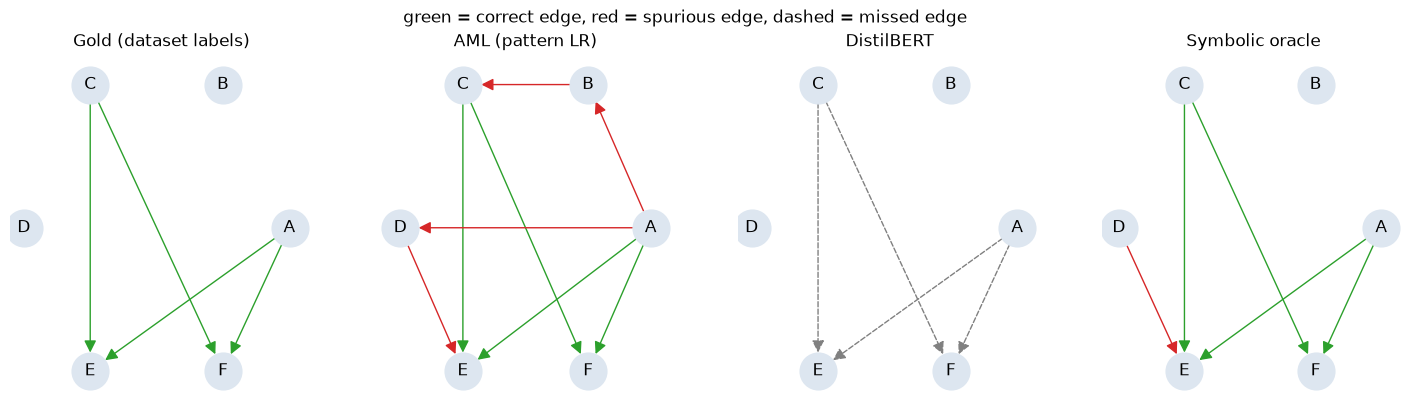

In [9]:
def gold_dag(doc):
    g = nx.DiGraph(list(gold_edges(doc)))
    g.add_nodes_from(parse_premise(doc.premise.iloc[0])[0])
    return g


def draw(ax, g, gold, title):
    pos = nx.circular_layout(sorted(g.nodes))
    nx.draw_networkx_nodes(g, pos, ax=ax, node_color="#dde6f0", node_size=700)
    nx.draw_networkx_labels(g, pos, ax=ax)
    for edges, style in [([e for e in g.edges if e in gold], dict(edge_color="tab:green")),
                         ([e for e in g.edges if e not in gold], dict(edge_color="tab:red")),
                         ([e for e in gold if e not in g.edges], dict(edge_color="grey", style="dashed"))]:
        nx.draw_networkx_edges(g, pos, edgelist=edges, ax=ax, arrowsize=18, node_size=700, **style)
    ax.set_title(title)
    ax.axis("off")


QUERY_DOCS = [d for d, g in test.groupby("doc_id") if len(gold_edges(g)) >= 3][:5]  # fixed rule, no cherry-picking
doc = test[test.doc_id == QUERY_DOCS[0]]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
draw(axes[0], gold_dag(doc), gold_edges(doc), "Gold (dataset labels)")
for ax, m in zip(axes[1:], SYSTEMS):
    draw(ax, graphs[m, "test"][QUERY_DOCS[0]], gold_edges(doc), m)
fig.suptitle("green = correct edge, red = spurious edge, dashed = missed edge")
fig.savefig(OUT / "dag_comparison.png", dpi=150, bbox_inches="tight")

## 5. Bayesian network + intervention queries
Gold BN: noisy-OR CPDs on the gold DAG, 5,000 simulated rows. Each system's DAG is fitted on the same
rows with pgmpy (MLE). Queries: ATE = P(Y=1 | do(X=1)) − P(Y=1 | do(X=0)) for every gold-connected pair.

In [10]:
tables = []
for k in ("test", "test_renamed"):
    df = evalsets[k]
    for d in QUERY_DOCS:
        t = query_table(gold_dag(df[df.doc_id == d]), {m: graphs[m, k][d] for m in SYSTEMS})
        tables.append(t.assign(set=k, doc_id=d))
queries = pd.concat(tables, ignore_index=True)
queries.to_csv(OUT / "intervention_queries.csv", index=False)
cols = ["gold_structure_fitted", *SYSTEMS]
queries[cols].sub(queries.gold, axis=0).abs().groupby(queries.set).mean().round(3).rename_axis("mean |ATE error|")

,gold_structure_fitted,AML (pattern LR),DistilBERT,Symbolic oracle
mean |ATE error|,,,,
test,0.004,0.005,0.063,0.005
test_renamed,0.005,0.238,0.189,0.004


In [11]:
for r in queries[queries.set == "test"].head(6).to_dict("records"):
    x, y = r["query"].removeprefix("ATE ").split("->")
    print(f"[{r['doc_id']}] forcing {x}=1 instead of {x}=0 changes P({y}=1) by {r['gold']:+.2f} (gold); "
          + ", ".join(f"{m}: {r[m]:+.2f}" for m in SYSTEMS))

[0d42fe0540] forcing A=1 instead of A=0 changes P(E=1) by +0.43 (gold); AML (pattern LR): +0.44, DistilBERT: +0.00, Symbolic oracle: +0.44
[0d42fe0540] forcing A=1 instead of A=0 changes P(F=1) by +0.43 (gold); AML (pattern LR): +0.42, DistilBERT: +0.00, Symbolic oracle: +0.42
[0d42fe0540] forcing C=1 instead of C=0 changes P(E=1) by +0.43 (gold); AML (pattern LR): +0.43, DistilBERT: +0.00, Symbolic oracle: +0.43
[0d42fe0540] forcing C=1 instead of C=0 changes P(F=1) by +0.43 (gold); AML (pattern LR): +0.44, DistilBERT: +0.00, Symbolic oracle: +0.44
[0d42fe0540] forcing E=1 instead of E=0 changes P(A=1) by +0.00 (gold); AML (pattern LR): +0.00, DistilBERT: +0.00, Symbolic oracle: +0.00
[0d42fe0540] forcing E=1 instead of E=0 changes P(C=1) by +0.00 (gold); AML (pattern LR): +0.00, DistilBERT: +0.00, Symbolic oracle: +0.00


## 6. Findings
- **Extraction (test, positive-class F1):** AML 0.617, DistilBERT 0.605, symbolic oracle 0.871. DistilBERT is much
  better on confounders (0.743 vs 0.000) and indirect causes (0.657 vs 0.452); AML is better on direct edges
  (0.703 vs 0.610) and colliders (0.667 vs 0.564).
- **Shortcut:** with variable letters shuffled, AML falls to 0.279 and DistilBERT to 0.264 while the oracle stays at
  0.871. For AML this is by construction: it was given the letter-order feature `x_before_y`, the only one of its
  features that renaming changes, and it relies on it. DistilBERT's drop mixes the same letter-order cue with an
  unfamiliar surface form: renamed premises list variables and pairs out of alphabetical order, which no training
  premise does. A renamed set re-sorted into alphabetical order would separate the two effects.
- **Graph:** edge precision AML 0.542, DistilBERT 0.505, oracle 0.890 (edge F1 0.703 / 0.610 / 0.942).
  DistilBERT's recall is nearly all-or-nothing per premise: 100% of the true edges on 9 of 13 premises, 0% on 2.
  On this data the review rules removed nothing (`removed_by_review` is 0 for every system and set). All 395 edges
  the text models propose point from an earlier to a later letter, and edges that follow one fixed order cannot form
  a cycle or a two-way pair; the oracle's edges all come from DAGs consistent with the premise. The acyclicity
  repair is therefore shown by the unit tests, not by these results.
- **Intervention queries (76 per set over 5 premises):** mean |ATE error| on test is AML 0.005, DistilBERT 0.063,
  oracle 0.005 (gold structure refitted: 0.004). With letters shuffled: AML 0.238, DistilBERT 0.189, oracle 0.004.
  Extra edges cost little because the fitted network learns they carry no effect; missing and reversed edges cost.
- **Reviewed edges** (`review/edge_review.csv`, 3 premises): AML 15 supported / 6 not, all 6 between connected
  variables whose direction the premise leaves open. DistilBERT 10 / 7, and 5 of those 7 join variables the premise
  states are independent. *Provenance:* these draft verdicts were derived from each premise's independence
  statements, using the same equivalence-class reasoning as the oracle, so they are not independent of it. They
  become a human review once the team has filled `team_verdict`.
- **Label audit** (`review/label_audit_review.csv`, 10 rows, same provenance): 5 labels contradict every DAG
  consistent with the premise; 5 match a looser definition of the relation. On the 388 test rows about indirect
  causes, reading "indirect cause" as "a directed path of length ≥ 2" agrees with 385 labels (99.2%) against 369
  (95.1%) for ours. Validation leans the same way by one row (333 vs 332 of 337), too little to justify a switch,
  so we keep the definition fixed before seeing test.
- **Limitations:** label noise; 37.7% of training pairs exceed 512 tokens and are truncated for DistilBERT; the gold
  graph holds only edges the text identifies; CPDs are synthetic, so ATE errors test structure, not the world.